# Analyse des produits cosmétiques collectés

Les données viennent du scraping du site (`src/scraper.py`). Le nettoyage est fait au début de ce notebook. Les prix sont en **pesos mexicains (MXN)**, la devise affichée par le site au moment de la collecte.

**Trois questions :**
1. Qu'est-ce qui explique le **prix** d'un produit ?
2. Peut-on reconnaître un **best-seller** à partir de sa fiche ?
3. Quels **groupes de produits** se dégagent ?

**Méthode.** Avec moins de 300 produits, un seul découpage train/test donne des scores très instables. Chaque modèle est donc évalué par **validation croisée imbriquée** :
- une boucle externe répétée (5 plis × 3 répétitions) mesure la performance ;
- une boucle interne règle les hyperparamètres sur les seules données d'entraînement de chaque pli.

Chaque modèle est comparé à une **référence simple**, et une graine unique (`SEED = 42`) rend les résultats reproductibles.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (KFold, StratifiedKFold, RepeatedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 42
np.random.seed(SEED)
FIG = Path('figures')
FIG.mkdir(exist_ok=True)
PALETTE = ['#1f5f6b', '#9a4a5c', '#6a8467', '#b0613c', '#5d6f80', '#c9a227']
sns.set_theme(style='whitegrid', palette=PALETTE)

## 0. Nettoyage

On lit le fichier le plus récent produit par le scraper (`data/raw/produits_*.csv`). À défaut, on lit les deux fichiers de la première collecte. Ensuite :
- les doublons sont supprimés ;
- le prix est converti en nombre (pesos mexicains) ;
- une note de 0, qui signifie « pas encore de note », devient une valeur manquante ;
- les listes d'ingrédients et de labels sont lues et comptées.

In [2]:
import ast, re
raw = Path('data/raw')
files = sorted(raw.glob('produits_*.csv'))
df = pd.read_csv(files[-1]) if files else pd.concat([pd.read_csv(raw / 'beauty.csv'),
                                                     pd.read_csv(raw / 'producthair.csv')], ignore_index=True)

def as_list(v):
    try:
        out = ast.literal_eval(str(v))
        return out if isinstance(out, list) else []
    except (ValueError, SyntaxError):
        return []

def parse_ingredients(text):
    # 'INGREDIENTS: A, B/C, ...' -> ['A', 'B'] (synonymes 'B/C' reduits au premier, sans doublon)
    if pd.isna(text) or str(text).strip() in ('', 'N/A'):
        return []
    text = re.sub(r'^ingredients\s*:\s*', '', str(text), flags=re.IGNORECASE)
    items = [p.split('/')[0].strip().upper().rstrip('.') for p in text.split(',')]
    return list(dict.fromkeys(i for i in items if i))

df['Name'] = df['Name'].astype(str).str.strip()
df = df.drop_duplicates(subset=['Category', 'Name', 'Price']).reset_index(drop=True)
df['Univers'] = np.where(df['Category'].isin(['Hair Tools', 'Hair Care']), 'Cheveux', 'Maquillage')
df['Prix_MXN'] = df['Price'].str.replace(',', '').str.extract(r'([\d.]+)', expand=False).astype(float)
df['Note'] = df['Stars'].replace(0, np.nan)
avis = df['Reviews'].map(as_list) if 'Reviews' in df else pd.Series([[]] * len(df))
df['Note_avis_visibles'] = avis.map(lambda r: np.mean([a['stars'] for a in r if a.get('stars')]) if r else np.nan)
ing = df['Ingredients'].map(parse_ingredients)
lab = df['Labels'].map(as_list)
df['Ingredients_liste'] = ing.map(' | '.join).replace('', np.nan)
df['Labels_liste'] = lab.map(lambda l: ' | '.join(sorted(set(l)))).replace('', np.nan)
df['Nb_ingredients'], df['Nb_labels'] = ing.map(len), lab.map(len)
df['Fiche_ingredients'] = (df['Nb_ingredients'] > 0).astype(int)
df['Best Seller'] = df['Best Seller'].fillna(0).astype(int)

print(len(df), 'produits |', df['Category'].nunique(), 'categories |', df['Subcategory'].nunique(), 'sous-categories')
print(df.groupby('Univers').size().to_string())

288 produits | 6 categories | 38 sous-categories
Univers
Cheveux        17
Maquillage    271


## 1. Vue d'ensemble

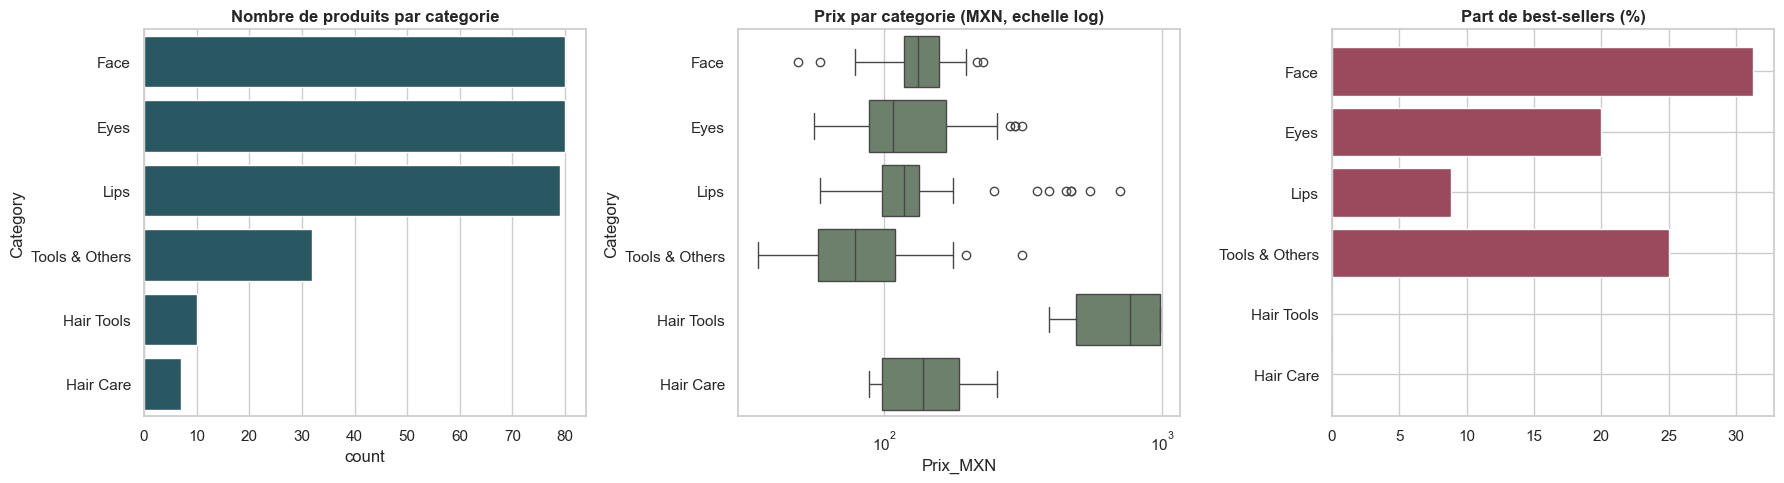

                Produits  Prix_median  Note_moyenne  Sans_note  Best_sellers
Category                                                                    
Eyes                  80       107.84          4.81         22            16
Face                  80       132.39          4.75         19            25
Hair Care              7       137.30          4.90          5             0
Hair Tools            10       765.96          4.91          2             0
Lips                  79       117.66          4.74         21             7
Tools & Others        32        78.37          4.79          4             8

Note moyenne des avis visibles : 4.98 -> la premiere page d avis ne montre presque que des 5 etoiles, variable non utilisee.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
order = df['Category'].value_counts().index
sns.countplot(data=df, y='Category', order=order, ax=axes[0], color=PALETTE[0])
axes[0].set_title('Nombre de produits par categorie', fontweight='bold')
sns.boxplot(data=df, y='Category', x='Prix_MXN', order=order, ax=axes[1], color=PALETTE[2])
axes[1].set_xscale('log')
axes[1].set_title('Prix par categorie (MXN, echelle log)', fontweight='bold')
bs = df.groupby('Category')['Best Seller'].mean().reindex(order) * 100
axes[2].barh(bs.index, bs.values, color=PALETTE[1])
axes[2].invert_yaxis()
axes[2].set_title('Part de best-sellers (%)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG / 'vue_ensemble.png', dpi=150, bbox_inches='tight')
plt.show()

summary = df.groupby('Category').agg(Produits=('Name', 'size'), Prix_median=('Prix_MXN', 'median'),
                                     Note_moyenne=('Note', 'mean'), Sans_note=('Note', lambda s: s.isna().sum()),
                                     Best_sellers=('Best Seller', 'sum')).round(2)
print(summary.to_string())
print('\nNote moyenne des avis visibles :', round(df['Note_avis_visibles'].mean(), 2),
      '-> la premiere page d avis ne montre presque que des 5 etoiles, variable non utilisee.')

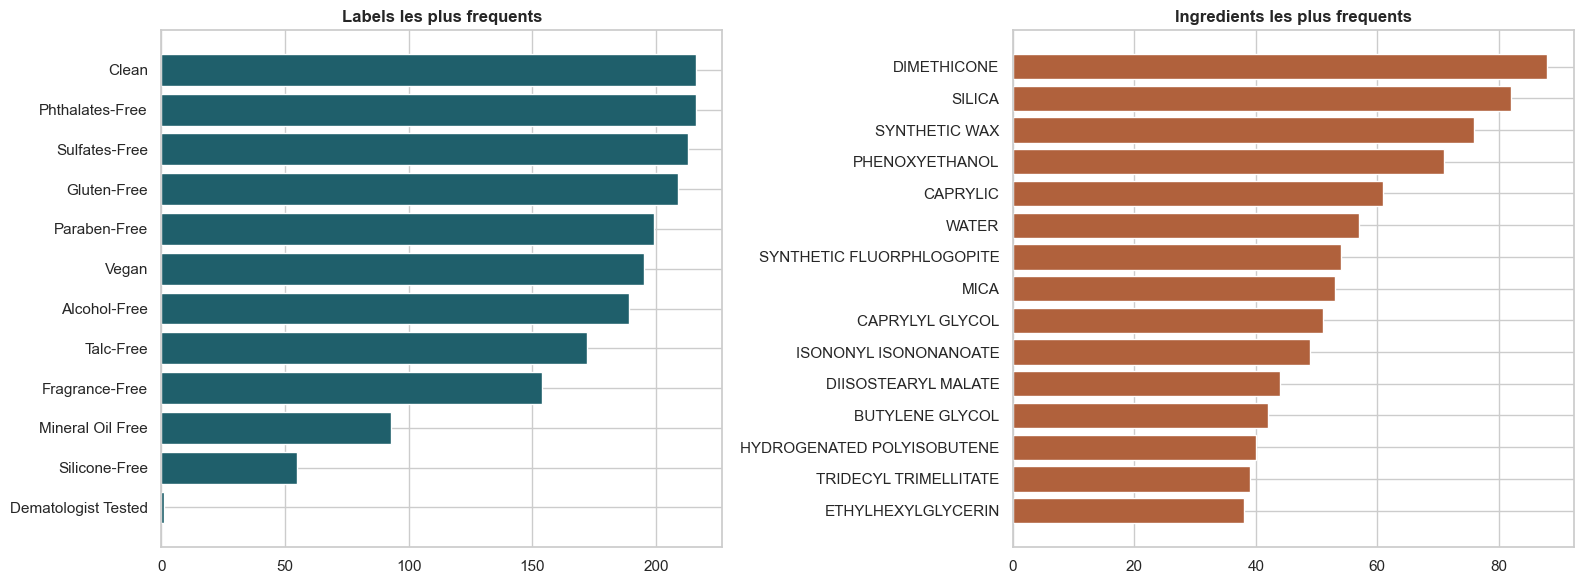

Produits avec une fiche ingredients : 241 / 288


In [4]:
labels = df['Labels_liste'].dropna().str.split(' \| ').explode().value_counts()
ingredients = df['Ingredients_liste'].dropna().str.split(' \| ').explode().value_counts()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(labels.index[:12][::-1], labels.values[:12][::-1], color=PALETTE[0])
axes[0].set_title('Labels les plus frequents', fontweight='bold')
axes[1].barh(ingredients.index[:15][::-1], ingredients.values[:15][::-1], color=PALETTE[3])
axes[1].set_title('Ingredients les plus frequents', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG / 'labels_ingredients.png', dpi=150, bbox_inches='tight')
plt.show()
print('Produits avec une fiche ingredients :', int(df['Fiche_ingredients'].sum()), '/', len(df))

## 2. Variables pour la modélisation

- **Catégorie et sous-catégorie**. Les sous-catégories de moins de 5 produits sont regroupées dans « Autre » pour éviter des colonnes presque vides.
- **Note** du produit. Les produits sans note ont leur note remplacée par la médiane, avec un indicateur « sans note ».
- **Nombre d'ingrédients**, **nombre de labels** et **présence d'une fiche ingrédients**.
- **Labels** fréquents (vegan, sans parfum, etc.), en indicateurs 0/1.

In [5]:
top_labels = [l for l in labels.index if labels[l] >= 20]
for l in top_labels:
    df['Label_' + l] = df['Labels_liste'].fillna('').str.split(' \| ').map(lambda x: int(l in x))
counts = df['Subcategory'].value_counts()
df['Sous_cat'] = df['Subcategory'].where(df['Subcategory'].map(counts) >= 5, 'Autre').fillna('Autre')
df['Sans_note'] = df['Note'].isna().astype(int)
df['log_prix'] = np.log(df['Prix_MXN'])

cat_cols = ['Category', 'Sous_cat']
num_cols = ['Note', 'Sans_note', 'Nb_ingredients', 'Nb_labels', 'Fiche_ingredients'] + ['Label_' + l for l in top_labels]

def preprocessor(extra_num=()):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols + list(extra_num)),
    ])

print('Labels retenus :', top_labels)
print('Sous-categories :', df['Sous_cat'].nunique())

Labels retenus : ['Clean', 'Phthalates-Free', 'Sulfates-Free', 'Gluten-Free', 'Paraben-Free', 'Vegan', 'Alcohol-Free', 'Talc-Free', 'Fragrance-Free', 'Mineral Oil Free', 'Silicone-Free']
Sous-categories : 19


## 3. Qu'est-ce qui explique le prix ?

La cible est le **logarithme du prix** : les écarts de prix sont multiplicatifs, et le logarithme réduit le poids des quelques produits très chers. Les erreurs sont reconverties en pesos.

| Modèle | Réglé dans la boucle interne |
|---|---|
| Référence : prix médian | rien |
| Ridge | force de régularisation `alpha` |
| Forêt aléatoire | profondeur, taille des feuilles, part des variables par nœud |
| Gradient Boosting | taux d'apprentissage, nombre de feuilles, taille des feuilles, régularisation L2 |

In [6]:
X, y = df[cat_cols + num_cols], df['log_prix']
outer = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
inner = KFold(n_splits=3, shuffle=True, random_state=SEED)

reg_models = {
    'Reference (mediane)': (DummyRegressor(strategy='median'), {}),
    'Ridge': (Ridge(), {'model__alpha': [0.01, 0.1, 1, 3, 10, 30, 100]}),
    'Foret aleatoire': (RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
                        {'model__max_depth': [3, 5, 8, None], 'model__min_samples_leaf': [1, 3, 5, 10],
                         'model__max_features': [0.3, 0.6, 1.0]}),
    'Gradient Boosting': (HistGradientBoostingRegressor(random_state=SEED, max_iter=300),
                          {'model__learning_rate': [0.03, 0.1], 'model__max_leaf_nodes': [7, 15, 31],
                           'model__min_samples_leaf': [5, 10, 20], 'model__l2_regularization': [0.0, 1.0]}),
}

def mae_mxn(est, X_, y_):
    return -np.mean(np.abs(np.exp(est.predict(X_)) - np.exp(y_)))

reg_rows = {}
for name, (model, grid) in reg_models.items():
    pipe = Pipeline([('prep', preprocessor()), ('model', model)])
    est = GridSearchCV(pipe, grid, cv=inner, scoring='neg_mean_absolute_error', n_jobs=-1) if grid else pipe
    res = cross_validate(est, X, y, cv=outer, scoring={'r2': 'r2', 'mae': mae_mxn}, n_jobs=1)
    reg_rows[name] = {'R2 (log prix)': res['test_r2'].mean(), 'R2 ecart-type': res['test_r2'].std(),
                      'Erreur moyenne (MXN)': -res['test_mae'].mean()}
    print(f"{name:<22} R2 = {res['test_r2'].mean():.3f} (+/- {res['test_r2'].std():.3f}) | "
          f"erreur moyenne = {-res['test_mae'].mean():.1f} MXN")
reg_df = pd.DataFrame(reg_rows).T

Reference (mediane)    R2 = -0.039 (+/- 0.037) | erreur moyenne = 61.5 MXN


Ridge                  R2 = 0.433 (+/- 0.129) | erreur moyenne = 47.5 MXN


Foret aleatoire        R2 = 0.431 (+/- 0.144) | erreur moyenne = 46.7 MXN


Gradient Boosting      R2 = 0.407 (+/- 0.132) | erreur moyenne = 46.8 MXN


Meilleur modele : Ridge | parametres : {'model__alpha': 1}


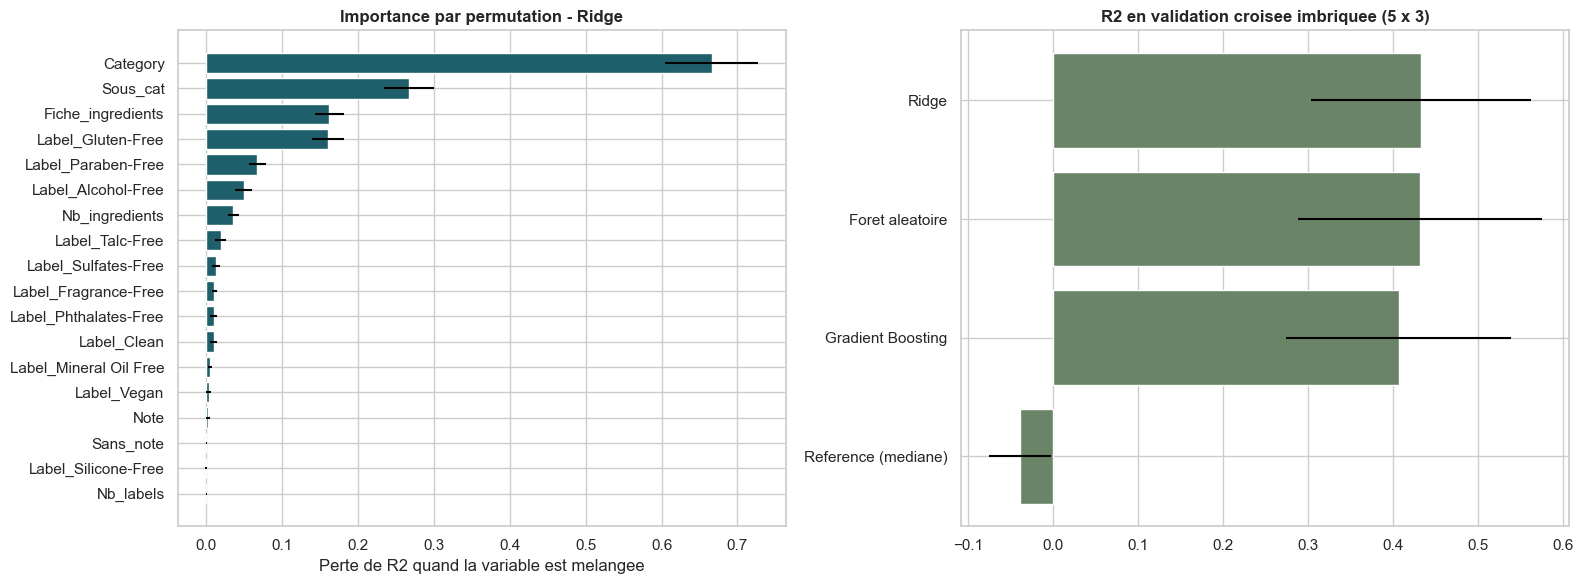

In [7]:
best_reg = reg_df['R2 (log prix)'].drop('Reference (mediane)').idxmax()
model, grid = reg_models[best_reg]
final_reg = GridSearchCV(Pipeline([('prep', preprocessor()), ('model', model)]), grid, cv=inner,
                         scoring='neg_mean_absolute_error', n_jobs=-1).fit(X, y)
print('Meilleur modele :', best_reg, '| parametres :', final_reg.best_params_)

pi = permutation_importance(final_reg.best_estimator_, X, y, n_repeats=20, random_state=SEED, scoring='r2')
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=X.columns)[imp.index], color=PALETTE[0])
axes[0].set_title(f'Importance par permutation - {best_reg}', fontweight='bold')
axes[0].set_xlabel('Perte de R2 quand la variable est melangee')
d = reg_df.sort_values('R2 (log prix)')
axes[1].barh(d.index, d['R2 (log prix)'], xerr=d['R2 ecart-type'], color=PALETTE[2])
axes[1].set_title('R2 en validation croisee imbriquee (5 x 3)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG / 'prix_modeles.png', dpi=150, bbox_inches='tight')
plt.show()

**Lecture.** Les trois modèles font nettement mieux que le prix médian (R² d'environ 0,43, contre un R² négatif pour la référence). L'erreur moyenne passe de 62 à environ 47 pesos.

- La **catégorie** et la **sous-catégorie** expliquent l'essentiel : un outil capillaire coûte plusieurs fois plus cher qu'un rouge à lèvres.
- Viennent ensuite la présence d'une **fiche ingrédients** et certains **labels**.
- La régression Ridge fait aussi bien que les modèles d'arbres : la relation est essentiellement additive, et le modèle le plus simple suffit.
- La dispersion entre les plis (± 0,13) rappelle qu'avec moins de 300 produits, ces chiffres restent indicatifs.

## 4. Reconnaître un best-seller

Seuls les produits de **maquillage** sont gardés : aucun produit capillaire n'est best-seller. Le prix est ajouté aux variables.

Les best-sellers représentent environ 20 % des produits. On regarde donc l'**AUC** (capacité à classer un best-seller avant un produit ordinaire) et la **PR-AUC**, à comparer à la proportion de best-sellers, qui est le score d'un classement au hasard.

| Modèle | Réglé dans la boucle interne |
|---|---|
| Référence : classe majoritaire | rien |
| Régression logistique | `C`, pénalité L1 (qui sélectionne elle-même les variables) ou L2, pondération des classes |
| Forêt aléatoire | profondeur, taille des feuilles, part des variables, pondération |
| Gradient Boosting | taux d'apprentissage, nombre de feuilles, taille des feuilles, pondération |

In [8]:
mk = df[df['Univers'] == 'Maquillage'].reset_index(drop=True)
Xc, yc = mk[cat_cols + num_cols + ['log_prix']], mk['Best Seller']
print(len(mk), 'produits de maquillage |', int(yc.sum()), 'best-sellers (', round(yc.mean() * 100, 1), '% )')

outer_c = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
inner_c = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
clf_models = {
    'Reference': (DummyClassifier(strategy='prior'), {}),
    'Regression logistique': (LogisticRegression(solver='liblinear', max_iter=2000),
                              {'model__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10], 'model__penalty': ['l1', 'l2'],
                               'model__class_weight': [None, 'balanced']}),
    'Foret aleatoire': (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                        {'model__max_depth': [3, 5, None], 'model__min_samples_leaf': [1, 3, 5, 10],
                         'model__max_features': [0.3, 0.6], 'model__class_weight': [None, 'balanced_subsample']}),
    'Gradient Boosting': (HistGradientBoostingClassifier(random_state=SEED, max_iter=200),
                          {'model__learning_rate': [0.03, 0.1], 'model__max_leaf_nodes': [7, 15],
                           'model__min_samples_leaf': [5, 10, 20], 'model__class_weight': [None, 'balanced']}),
}
clf_rows = {}
for name, (model, grid) in clf_models.items():
    pipe = Pipeline([('prep', preprocessor(['log_prix'])), ('model', model)])
    est = GridSearchCV(pipe, grid, cv=inner_c, scoring='roc_auc', n_jobs=-1) if grid else pipe
    res = cross_validate(est, Xc, yc, cv=outer_c, scoring={'auc': 'roc_auc', 'ap': 'average_precision'}, n_jobs=1)
    clf_rows[name] = {'AUC': res['test_auc'].mean(), 'AUC ecart-type': res['test_auc'].std(), 'PR-AUC': res['test_ap'].mean()}
    print(f"{name:<22} AUC = {res['test_auc'].mean():.3f} (+/- {res['test_auc'].std():.3f}) | PR-AUC = {res['test_ap'].mean():.3f}")
clf_df = pd.DataFrame(clf_rows).T
print('PR-AUC d un classement au hasard :', round(yc.mean(), 3))

271 produits de maquillage | 56 best-sellers ( 20.7 % )


Reference              AUC = 0.500 (+/- 0.000) | PR-AUC = 0.207


Regression logistique  AUC = 0.643 (+/- 0.064) | PR-AUC = 0.362


Foret aleatoire        AUC = 0.653 (+/- 0.084) | PR-AUC = 0.400


Gradient Boosting      AUC = 0.635 (+/- 0.080) | PR-AUC = 0.378
PR-AUC d un classement au hasard : 0.207


Meilleur modele : Foret aleatoire | parametres : {'model__class_weight': 'balanced_subsample', 'model__max_depth': None, 'model__max_features': 0.6, 'model__min_samples_leaf': 5}


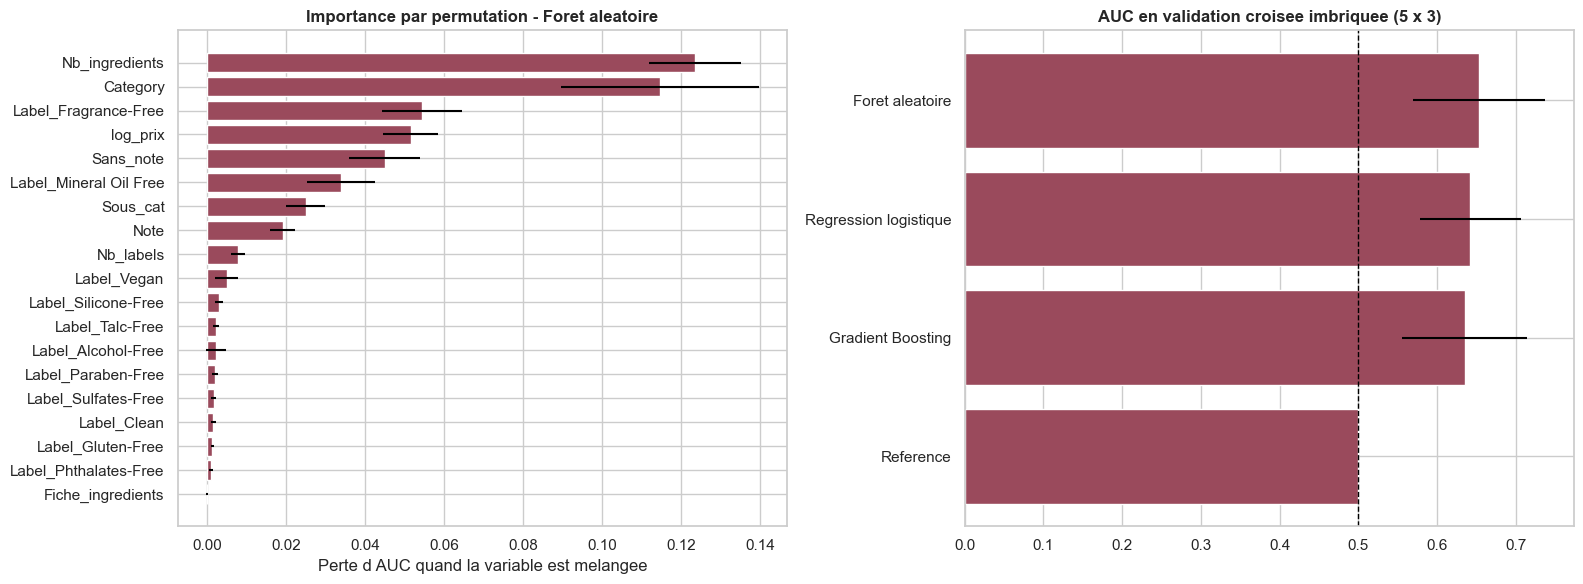


Taux de best-sellers selon la presence d une note :
Sans_note
avec note    23.4
sans note    12.1


In [9]:
best_clf = clf_df['AUC'].drop('Reference').idxmax()
model, grid = clf_models[best_clf]
final_clf = GridSearchCV(Pipeline([('prep', preprocessor(['log_prix'])), ('model', model)]), grid, cv=inner_c,
                         scoring='roc_auc', n_jobs=-1).fit(Xc, yc)
print('Meilleur modele :', best_clf, '| parametres :', final_clf.best_params_)
pi = permutation_importance(final_clf.best_estimator_, Xc, yc, n_repeats=20, random_state=SEED, scoring='roc_auc')
imp = pd.Series(pi.importances_mean, index=Xc.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=Xc.columns)[imp.index], color=PALETTE[1])
axes[0].set_title(f'Importance par permutation - {best_clf}', fontweight='bold')
axes[0].set_xlabel('Perte d AUC quand la variable est melangee')
d = clf_df.sort_values('AUC')
axes[1].barh(d.index, d['AUC'], xerr=d['AUC ecart-type'], color=PALETTE[1])
axes[1].axvline(0.5, color='black', ls='--', lw=1)
axes[1].set_title('AUC en validation croisee imbriquee (5 x 3)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG / 'best_seller_modeles.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nTaux de best-sellers selon la presence d une note :')
print((mk.groupby('Sans_note')['Best Seller'].mean() * 100).round(1).rename({0: 'avec note', 1: 'sans note'}).to_string())

**Lecture.** Le signal est faible mais réel :
- la meilleure AUC (forêt aléatoire, environ 0,65) est au-dessus du hasard (0,5) ;
- la PR-AUC (0,40) est presque le double de la proportion de best-sellers (0,21).

L'écart entre les plis reste grand (± 0,08). La variable la plus parlante est la **présence d'une note** : 23 % de best-sellers parmi les produits notés, contre 12 % parmi les autres. C'est logique, puisqu'un produit qui se vend reçoit des avis. Autrement dit, la composition d'un produit ne suffit pas à prédire son succès commercial.

## 5. Groupes de produits (K-Means)

La segmentation porte sur les **241 produits qui ont une fiche ingrédients**. Sans cette restriction, l'algorithme sépare simplement le maquillage des accessoires, ce qui n'apprend rien. Les variables sont le logarithme du prix, la note, le nombre d'ingrédients et le nombre de labels, toutes standardisées. Le nombre de groupes `k` n'est pas fixé à l'avance. On le choisit avec deux critères :
- le **score de silhouette** : les groupes sont-ils bien séparés ?
- la **stabilité** : retrouve-t-on les mêmes groupes sur 30 rééchantillonnages ? Elle se mesure par l'indice de Rand ajusté (ARI), où 1 signifie des groupes identiques.

Chaque K-Means est lancé 50 fois depuis des points de départ différents (`n_init=50`, graine fixe), et on garde le meilleur résultat.

   Silhouette  Stabilite (ARI)
k                             
2       0.411            0.738
3       0.270            0.579
4       0.291            0.756
5       0.289            0.684
6       0.283            0.642
7       0.248            0.538
8       0.252            0.563

k retenu (meilleure silhouette parmi les solutions stables) : 2


        Produits  Prix_median  Note  Ingredients  Labels  Best_sellers_pct Categorie principale
Groupe                                                                                         
1            216       117.66  4.76        11.03    8.86             19.44                 Eyes
2             25       117.66  4.80        10.84    0.00             24.00                 Lips


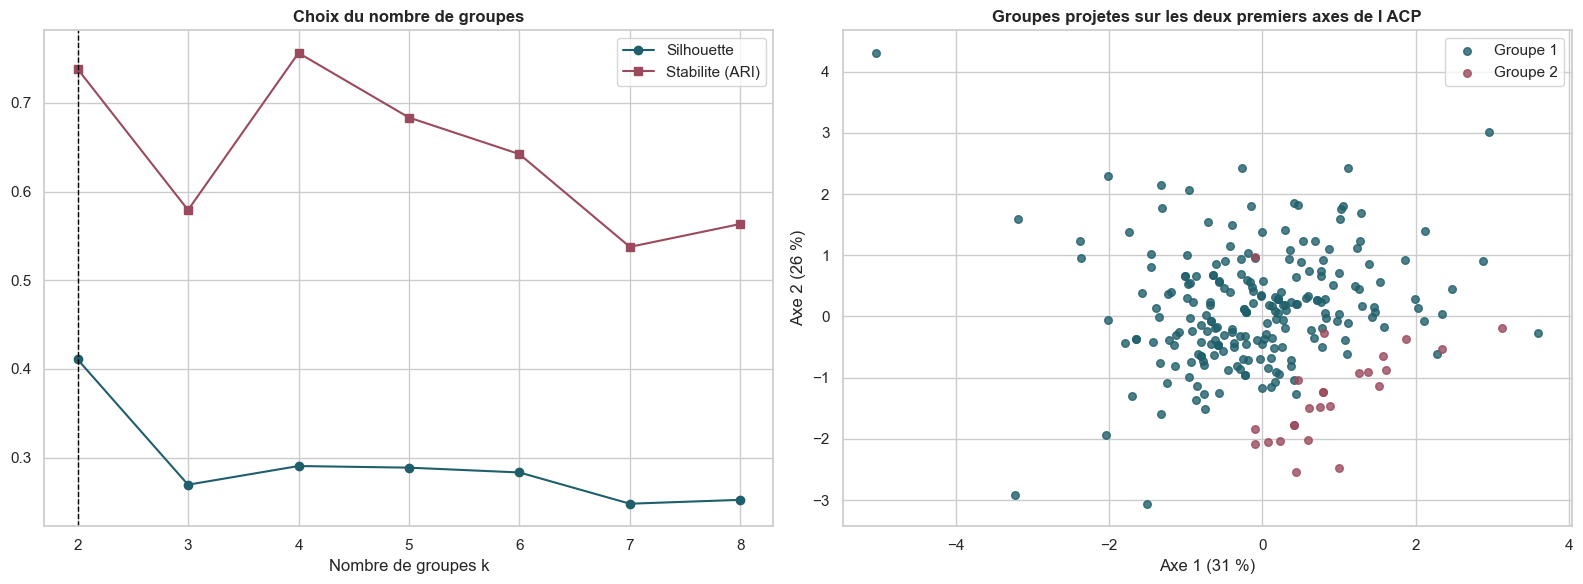

In [10]:
seg = df[df['Fiche_ingredients'] == 1].copy()
seg_cols = ['log_prix', 'Note', 'Nb_ingredients', 'Nb_labels']
Z = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]).fit_transform(seg[seg_cols])
rng = np.random.RandomState(SEED)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    aris = []
    for b in range(30):
        idx = rng.choice(len(Z), len(Z), replace=True)
        kb = KMeans(n_clusters=k, n_init=10, random_state=SEED + b).fit(Z[idx])
        aris.append(adjusted_rand_score(km.labels_, kb.predict(Z)))
    rows.append({'k': k, 'Silhouette': silhouette_score(Z, km.labels_), 'Stabilite (ARI)': np.mean(aris)})
k_df = pd.DataFrame(rows).set_index('k')
print(k_df.round(3).to_string())
stable = k_df[k_df['Stabilite (ARI)'] >= 0.8]
best_k = int((stable if len(stable) else k_df)['Silhouette'].idxmax())
print('\nk retenu (meilleure silhouette parmi les solutions stables) :', best_k)

km = KMeans(n_clusters=best_k, n_init=50, random_state=SEED).fit(Z)
seg['Groupe'] = km.labels_ + 1
profile = seg.groupby('Groupe').agg(Produits=('Name', 'size'), Prix_median=('Prix_MXN', 'median'),
                                   Note=('Note', 'mean'), Ingredients=('Nb_ingredients', 'mean'),
                                   Labels=('Nb_labels', 'mean'),
                                   Best_sellers_pct=('Best Seller', lambda s: s.mean() * 100)).round(2)
profile['Categorie principale'] = seg.groupby('Groupe')['Category'].agg(lambda s: s.value_counts().index[0])
print(profile.to_string())

pcs = PCA(n_components=2, random_state=SEED).fit(Z)
P = pcs.transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(k_df.index, k_df['Silhouette'], marker='o', label='Silhouette', color=PALETTE[0])
axes[0].plot(k_df.index, k_df['Stabilite (ARI)'], marker='s', label='Stabilite (ARI)', color=PALETTE[1])
axes[0].axvline(best_k, color='black', ls='--', lw=1)
axes[0].set_xlabel('Nombre de groupes k')
axes[0].legend()
axes[0].set_title('Choix du nombre de groupes', fontweight='bold')
for g in sorted(seg['Groupe'].unique()):
    m = (seg['Groupe'] == g).to_numpy()
    axes[1].scatter(P[m, 0], P[m, 1], s=30, alpha=0.8, color=PALETTE[(g - 1) % len(PALETTE)], label=f'Groupe {g}')
axes[1].set_xlabel(f'Axe 1 ({pcs.explained_variance_ratio_[0] * 100:.0f} %)')
axes[1].set_ylabel(f'Axe 2 ({pcs.explained_variance_ratio_[1] * 100:.0f} %)')
axes[1].legend()
axes[1].set_title('Groupes projetes sur les deux premiers axes de l ACP', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG / 'segmentation.png', dpi=150, bbox_inches='tight')
plt.show()

**Lecture.** Aucune solution n'est vraiment stable : l'indice de Rand ajusté reste sous 0,8 pour tous les `k`. La solution la moins mauvaise (k = 2) sépare surtout les produits **avec labels** (216) de ceux **sans labels** (25), à prix et notes comparables.

Conclusion honnête : au-delà de la catégorie et des labels, les produits de cette marque **ne forment pas de groupes naturels**. La gamme est homogène en prix et en notes, et les groupes de la première version (k = 4 fixé à l'avance, sans test de stabilité) ne tenaient pas.

## 6. Ce qui a été retiré de la première version, et pourquoi

- **Prédiction de la note des avis (R² de 1,00).** Ce score parfait venait d'un bug et non d'un bon modèle. Le code cherchait une clé `score` dans les avis, alors que le scraper les enregistre sous `stars`. La note valait donc toujours la même valeur, et prédire une constante est trivial. De plus, les avis visibles sont presque tous à 5 étoiles : il n'y a rien à prédire.
- **Régression du prix des produits capillaires.** Sur 17 produits avec un seul découpage, le R² était négatif (-0,36) : impossible de conclure avec si peu de données. Les produits capillaires sont maintenant inclus dans le modèle de prix global.
- **Évaluation sur un seul découpage** (par exemple 55 produits de test, dont 10 best-sellers). Elle est remplacée par la validation croisée imbriquée répétée.

## 7. Conclusion

- **Collecte automatisée** : `src/scraper.py` collecte les produits en une commande, avec reprise sur erreur, pauses entre les requêtes et journalisation.
- **Prix** : il dépend surtout de la catégorie et de la sous-catégorie. Un modèle linéaire régularisé explique environ 43 % de la variance du logarithme du prix.
- **Best-sellers** : la fiche produit seule ne suffit pas à les reconnaître (AUC d'environ 0,65). Le succès commercial dépend d'éléments absents des données : prix promotionnels, visibilité, réseaux sociaux.
- **Segmentation** : il n'existe pas de groupes stables au-delà de la catégorie et des labels.

**Pour aller plus loin** : collecter toutes les pages d'avis (nombre réel et répartition des notes) et suivre les prix dans le temps, en relançant le scraper chaque semaine.